# Partie B — Exploration de 29 algorithmes de Machine Learning



Sources : [scikit-learn datasets](https://scikit-learn.org/stable/datasets/real_world.html), [Gymnasium Taxi](https://gymnasium.farama.org/environments/toy_text/taxi/).

In [54]:
!pip -q install scikit-learn xgboost umap-learn gymnasium

In [96]:
import warnings, sys, sklearn, matplotlib
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_score, KFold, StratifiedKFold
from matplotlib.patches import FancyBboxPatch, Ellipse, Circle
plt.rcParams.update({'figure.dpi':100,'axes.grid':True,'grid.alpha':.3,'font.size':9})

# Q0 — les données utilisées par les démonstrations, mises sous forme de DataFrame
df_reg  = pd.DataFrame(X_reg, columns=jeu_reg.feature_names); df_reg['cible'] = y_reg
df_cls  = pd.DataFrame(X_cls, columns=jeu_cls.feature_names); df_cls['cible'] = y_cls
df_wine = pd.DataFrame(jeu_groupes.data, columns=jeu_groupes.feature_names); df_wine['cultivar'] = jeu_groupes.target
df_wine_acp = pd.DataFrame(X_clu, columns=['CP1','CP2'])
df_dig  = pd.DataFrame(jeu_images.data, columns=[f'px{i}' for i in range(64)]); df_dig['chiffre'] = jeu_images.target

def q0(nom, n=5):
    d = {'reg':df_reg, 'cls':df_cls, 'wine':df_wine, 'wine_acp':df_wine_acp, 'dig':df_dig}[nom]
    print('Dimensions :', d.shape); display(d.head(n))

def flux(etapes, titre, legende=None, boucle=False, couleurs=None):
    """Schéma de flux : une boîte par étape, flèches entre étapes (boucle=True : flèche de retour)."""
    n = len(etapes); fig, ax = plt.subplots(figsize=(min(2.3*n, 13), 2.6)); ax.axis('off')
    couleurs = couleurs or ['#dbe9f6']*n
    for i, e in enumerate(etapes):
        ax.add_patch(FancyBboxPatch((i*2.3, 0), 1.9, 1.2, boxstyle='round,pad=0.05', fc=couleurs[i], ec='#2b4c7e'))
        ax.text(i*2.3+0.95, 0.6, e, ha='center', va='center', fontsize=8, wrap=True)
        if i < n-1: ax.annotate('', xy=(i*2.3+2.3, 0.6), xytext=(i*2.3+1.95, 0.6), arrowprops=dict(arrowstyle='->', lw=1.5))
    if boucle: ax.annotate('', xy=(0.95, -0.05), xytext=((n-1)*2.3+0.95, -0.05),
                           arrowprops=dict(arrowstyle='->', lw=1.2, connectionstyle='arc3,rad=0.25', color='#c0392b'))
    ax.set_xlim(-0.2, n*2.3); ax.set_ylim(-1.2 if boucle else -0.3, 1.5); ax.set_title(titre, fontsize=11)
    if legende: ax.text(0, -1.1 if boucle else -0.25, legende, fontsize=8, style='italic', va='top')
    plt.show()

def variation(fabrique, nom_param, valeurs, X, y, scoring, classif=False):
    """Q4 — variation d'un hyperparamètre en validation croisée 5 plis sur l'ENTRAÎNEMENT (le test n'est pas utilisé)."""
    cv = StratifiedKFold(5, shuffle=True, random_state=GRAINE) if classif else KFold(5, shuffle=True, random_state=GRAINE)
    lignes = []
    for v in valeurs:
        s = cross_val_score(fabrique(v), X, y, cv=cv, scoring=scoring)
        s = -s if scoring.startswith('neg_') else s
        lignes.append((str(v), s.mean(), s.std()))
    t = pd.DataFrame(lignes, columns=[nom_param, 'moyenne CV', 'écart-type'])
    display(t.round(4))
    plt.figure(figsize=(5, 2.8)); plt.errorbar(t[nom_param], t['moyenne CV'], yerr=t['écart-type'], marker='o', capsize=3)
    plt.xlabel(nom_param); plt.ylabel(scoring.replace('neg_', '')); plt.title(f'Effet de {nom_param} (CV 5 plis, entraînement)'); plt.show()
    return t

print('Python', sys.version.split()[0], '| numpy', np.__version__, '| pandas', pd.__version__,
      '| scikit-learn', sklearn.__version__, '| matplotlib', matplotlib.__version__)

Python 3.13.18 | numpy 2.4.6 | pandas 2.2.3 | scikit-learn 1.6.1 | matplotlib 3.10.0


In [56]:
from sklearn.datasets import load_diabetes, load_breast_cancer, load_wine, load_digits
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

jeu_reg = load_diabetes()
X_reg, y_reg = jeu_reg.data, jeu_reg.target
jeu_cls = load_breast_cancer()
X_cls, y_cls = jeu_cls.data, jeu_cls.target
jeu_groupes = load_wine()
X_clu = PCA(n_components=2, random_state=GRAINE).fit_transform(StandardScaler().fit_transform(jeu_groupes.data))
jeu_images = load_digits()
X_images = StandardScaler().fit_transform(jeu_images.data)
Xr_ent, Xr_test, yr_ent, yr_test = train_test_split(X_reg, y_reg, test_size=0.25, random_state=GRAINE)
Xc_ent, Xc_test, yc_ent, yc_test = train_test_split(X_cls, y_cls, test_size=0.25, stratify=y_cls, random_state=GRAINE)
print('Variables re-définies avec succès !')

Variables re-définies avec succès !


In [57]:
# Jeux publics de scikit-learn : pas de téléchargement ni de compte requis
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes, load_breast_cancer, load_wine, load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, f1_score, silhouette_score, accuracy_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.decomposition import PCA
GRAINE = 42

jeu_reg = load_diabetes()
X_reg, y_reg = jeu_reg.data, jeu_reg.target
jeu_cls = load_breast_cancer()
X_cls, y_cls = jeu_cls.data, jeu_cls.target
jeu_groupes = load_wine()
X_clu = PCA(n_components=2, random_state=GRAINE).fit_transform(StandardScaler().fit_transform(jeu_groupes.data))
jeu_images = load_digits()
X_images = StandardScaler().fit_transform(jeu_images.data)
Xr_ent, Xr_test, yr_ent, yr_test = train_test_split(X_reg,y_reg,test_size=.25,random_state=GRAINE)
Xc_ent, Xc_test, yc_ent, yc_test = train_test_split(X_cls,y_cls,test_size=.25,stratify=y_cls,random_state=GRAINE)
print('Diabetes',X_reg.shape,'Breast cancer',X_cls.shape,'Wine',X_clu.shape,'Digits',X_images.shape)

Diabetes (442, 10) Breast cancer (569, 30) Wine (178, 2) Digits (1797, 64)


## 1. Régression linéaire

**Question ciblée (Partie B) :** Expliquez pourquoi une relation linéaire entre les variables médicales et la cible peut être insuffisante.

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [58]:
from sklearn.linear_model import LinearRegression
modele=LinearRegression().fit(Xr_ent,yr_ent)
pred=modele.predict(Xr_test)
print('RMSE:',mean_squared_error(yr_test,pred)**.5,'R²:',r2_score(yr_test,pred))

RMSE: 53.369566710321955 R²: 0.4849058889476756


## 2. Ridge

**Question ciblée (Partie B) :** Que se passe-t-il lorsque la pénalisation L2 devient très forte ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [59]:
from sklearn.linear_model import Ridge
modele=make_pipeline(StandardScaler(),Ridge(alpha=25.)).fit(Xr_ent,yr_ent)
print('MAE:',mean_absolute_error(yr_test,modele.predict(Xr_test)))

MAE: 41.49082128021844


## 3. Lasso

**Question ciblée (Partie B) :** Comment la pénalisation L1 sélectionne-t-elle des variables ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [60]:
from sklearn.linear_model import Lasso
modele=make_pipeline(StandardScaler(),Lasso(alpha=3.,max_iter=15000)).fit(Xr_ent,yr_ent)
print('R²:',r2_score(yr_test,modele.predict(Xr_test)))

R²: 0.5013056660042327


## 4. Régression polynomiale

**Question ciblée (Partie B) :** Quelle difficulté pose la croissance du nombre de caractéristiques polynomiales ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [61]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge
modele=make_pipeline(StandardScaler(),PolynomialFeatures(degree=2,include_bias=False),Ridge(alpha=60.)).fit(Xr_ent,yr_ent)
print('MAE:',mean_absolute_error(yr_test,modele.predict(Xr_test)))

MAE: 41.24579873763898


## 5. Arbre de régression

**Question ciblée (Partie B) :** Pourquoi limiter la profondeur et le nombre minimal d’observations par feuille ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [62]:
from sklearn.tree import DecisionTreeRegressor
modele=DecisionTreeRegressor(max_depth=3,min_samples_leaf=8,random_state=GRAINE).fit(Xr_ent,yr_ent)
print('R²:',r2_score(yr_test,modele.predict(Xr_test)))

R²: 0.4314003646672102


## 6. Forêt aléatoire — régression

**Question ciblée (Partie B) :** Décrivez le bootstrap et expliquez le rôle de la moyenne des arbres.

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [63]:
from sklearn.ensemble import RandomForestRegressor
modele=RandomForestRegressor(n_estimators=120,min_samples_leaf=4,random_state=GRAINE,n_jobs=-1).fit(Xr_ent,yr_ent)
print('MAE:',mean_absolute_error(yr_test,modele.predict(Xr_test)))

MAE: 42.58294190565993


## 7. Gradient Boosting — régression

**Question ciblée (Partie B) :** Pourquoi les arbres sont-ils entraînés séquentiellement dans le boosting ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [64]:
from sklearn.ensemble import HistGradientBoostingRegressor
modele=HistGradientBoostingRegressor(max_iter=110,max_leaf_nodes=12,random_state=GRAINE).fit(Xr_ent,yr_ent)
print('RMSE:',mean_squared_error(yr_test,modele.predict(Xr_test))**.5)

RMSE: 57.12732848789662


## 8. Régression logistique

**Question ciblée (Partie B) :** Comment interpréter une probabilité prédite et ajuster le seuil de classification ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [65]:
from sklearn.linear_model import LogisticRegression
modele=make_pipeline(StandardScaler(),LogisticRegression(C=.2,max_iter=1500,random_state=GRAINE)).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

F1: 0.9888888888888889


## 9. KNN

**Question ciblée (Partie B) :** Quel est l’effet d’une distance normalisée et du nombre de voisins ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [66]:
from sklearn.neighbors import KNeighborsClassifier
modele=make_pipeline(StandardScaler(),KNeighborsClassifier(n_neighbors=9,weights='distance')).fit(Xc_ent,yc_ent)
print('Exactitude:',accuracy_score(yc_test,modele.predict(Xc_test)))

Exactitude: 0.965034965034965


## 10. Naive Bayes

**Question ciblée (Partie B) :** Quelle hypothèse d’indépendance conditionnelle est faite par Naive Bayes ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [67]:
from sklearn.naive_bayes import GaussianNB
modele=GaussianNB(var_smoothing=1e-8).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

F1: 0.9621621621621622


## 11. Arbre de décision

**Question ciblée (Partie B) :** Comment calculer l’impureté de Gini et choisir une séparation ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [68]:
from sklearn.tree import DecisionTreeClassifier
modele=DecisionTreeClassifier(max_depth=3,min_samples_leaf=5,random_state=GRAINE).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

F1: 0.9560439560439561


## 12. Forêt aléatoire — classification

**Question ciblée (Partie B) :** Pourquoi une forêt est-elle généralement moins instable qu’un arbre seul ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [69]:
from sklearn.ensemble import RandomForestClassifier
modele=RandomForestClassifier(n_estimators=110,max_depth=6,random_state=GRAINE,n_jobs=-1).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

F1: 0.9613259668508287


## 13. SVM

**Question ciblée (Partie B) :** À quoi servent les vecteurs de support et le paramètre C ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [70]:
from sklearn.svm import SVC
modele=make_pipeline(StandardScaler(),SVC(kernel='rbf',C=2.,gamma='scale')).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

F1: 0.9888888888888889


## 14. Gradient Boosting — classification

**Question ciblée (Partie B) :** Comment corriger progressivement les erreurs de classification ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [71]:
from sklearn.ensemble import HistGradientBoostingClassifier
modele=HistGradientBoostingClassifier(max_iter=100,max_leaf_nodes=10,random_state=GRAINE).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

F1: 0.9726775956284153


## 15. AdaBoost

**Question ciblée (Partie B) :** Comment AdaBoost repondère-t-il les exemples difficiles ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [72]:
from sklearn.ensemble import AdaBoostClassifier
modele=AdaBoostClassifier(n_estimators=90,learning_rate=.7,random_state=GRAINE).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

F1: 0.9726775956284153


## 16. XGBoost

**Question ciblée (Partie B) :** Quel est le rôle de la régularisation et du learning_rate dans XGBoost ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [73]:
from xgboost import XGBClassifier
modele=XGBClassifier(n_estimators=100,max_depth=2,learning_rate=.09,random_state=GRAINE,eval_metric='logloss').fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

F1: 0.978021978021978


## 17. K-means

**Question ciblée (Partie B) :** Comment affecter chaque vin à son centroïde puis recalculer celui-ci ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

Silhouette: 0.5610505693103246


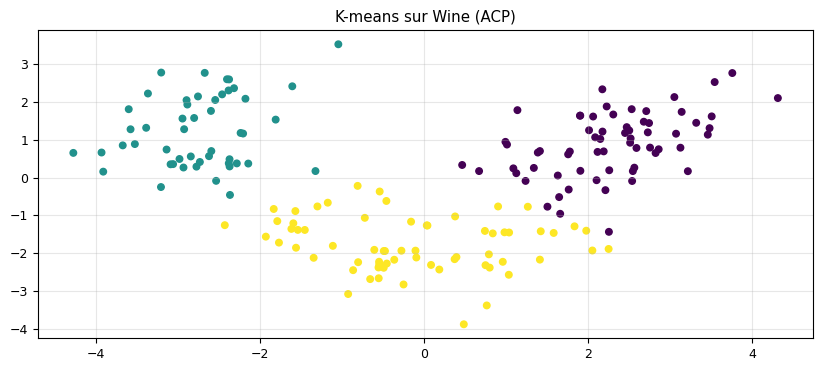

In [74]:
from sklearn.cluster import KMeans
modele=KMeans(n_clusters=3,n_init=15,random_state=GRAINE).fit(X_clu)
print('Silhouette:',silhouette_score(X_clu,modele.labels_))
plt.scatter(X_clu[:,0],X_clu[:,1],c=modele.labels_,s=22);plt.title('K-means sur Wine (ACP)');plt.show()

## 18. Classification hiérarchique

**Question ciblée (Partie B) :** Que montre un dendrogramme et comment définit-on le lien de Ward ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [75]:
from sklearn.cluster import AgglomerativeClustering
etiquettes=AgglomerativeClustering(n_clusters=3,linkage='ward').fit_predict(X_clu)
print('Silhouette:',silhouette_score(X_clu,etiquettes))

Silhouette: 0.5590883962040383


## 19. DBSCAN

**Question ciblée (Partie B) :** À quoi correspondent les points marqués comme bruit par DBSCAN ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [76]:
from sklearn.cluster import DBSCAN
etiquettes=DBSCAN(eps=.7,min_samples=6).fit_predict(X_clu)
print('Groupes:',len(set(etiquettes)-{-1}),'Bruit:',int((etiquettes==-1).sum()))

Groupes: 2 Bruit: 8


## 20. Mélanges gaussiens

**Question ciblée (Partie B) :** En quoi les appartenances probabilistes diffèrent-elles d’une affectation dure ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [77]:
from sklearn.mixture import GaussianMixture
modele=GaussianMixture(n_components=3,covariance_type='full',random_state=GRAINE).fit(X_clu)
etiquettes=modele.predict(X_clu)
print('Poids des groupes:',modele.weights_.round(3),'Silhouette:',silhouette_score(X_clu,etiquettes))

Poids des groupes: [0.38  0.269 0.351] Silhouette: 0.5591116207103001


## 21. ACP

**Question ciblée (Partie B) :** Que mesure la variance expliquée par les deux axes de l’ACP ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

Variance expliquée: [0.12  0.096]


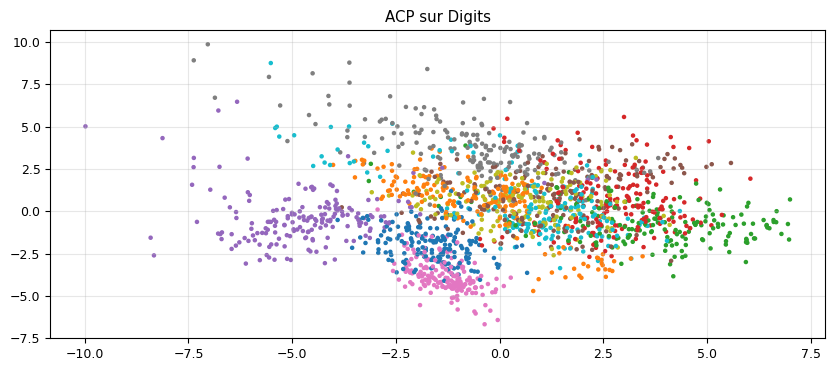

In [78]:
from sklearn.decomposition import PCA
modele=PCA(n_components=2,random_state=GRAINE).fit(X_images)
projection=modele.transform(X_images)
print('Variance expliquée:',modele.explained_variance_ratio_.round(3))
plt.scatter(projection[:,0],projection[:,1],c=jeu_images.target,cmap='tab10',s=5);plt.title('ACP sur Digits');plt.show()

## 22. t-SNE

**Question ciblée (Partie B) :** Pourquoi la distance entre groupes éloignés peut-elle être trompeuse en t-SNE ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

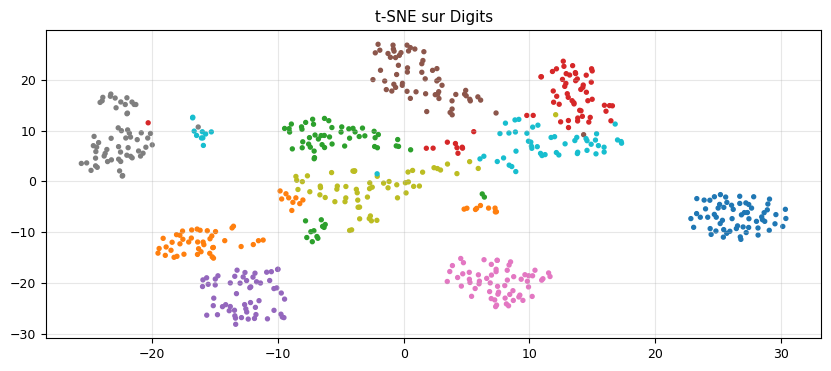

In [79]:
from sklearn.manifold import TSNE
projection=TSNE(n_components=2,perplexity=35,random_state=GRAINE,init='pca').fit_transform(X_images[:600])
plt.scatter(projection[:,0],projection[:,1],c=jeu_images.target[:600],cmap='tab10',s=8);plt.title('t-SNE sur Digits');plt.show()

## 23. UMAP

**Question ciblée (Partie B) :** Quel est l’effet de n_neighbors et min_dist sur les voisinages ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

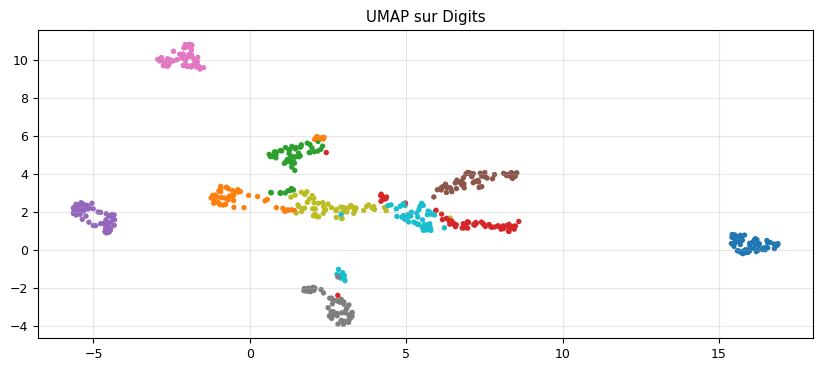

In [80]:
import umap
projection=umap.UMAP(n_components=2,n_neighbors=20,min_dist=.15,random_state=GRAINE).fit_transform(X_images[:600])
plt.scatter(projection[:,0],projection[:,1],c=jeu_images.target[:600],cmap='tab10',s=8);plt.title('UMAP sur Digits');plt.show()

## 24. Isolation Forest

**Question ciblée (Partie B) :** Pourquoi une observation statistiquement atypique n’est-elle pas forcément une erreur ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [81]:
from sklearn.ensemble import IsolationForest
# Recherche d'observations atypiques dans les caractéristiques de vins (sans ajouter de faux points)
modele=IsolationForest(contamination=.05,n_estimators=150,random_state=GRAINE).fit(X_clu)
indices=np.where(modele.predict(X_clu)==-1)[0]
print('Nombre de vins atypiques:',len(indices),'Indices (extrait):',indices[:12])

Nombre de vins atypiques: 9 Indices (extrait): [  3  14  18  59  80 115 146 158 177]


## 25. Bandits manchots

**Question ciblée (Partie B) :** Comment calculer une estimation du gain moyen de chaque bras ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [82]:
# Bandit simulé à 4 choix : la politique choisit successivement chaque bras
generateur=np.random.default_rng(GRAINE)
probabilites=np.array([.15,.4,.6,.75]);sommes=np.zeros(4);comptes=np.zeros(4,dtype=int)
for t in range(800):
    bras=t%4
    gain=int(generateur.random()<probabilites[bras]);sommes[bras]+=gain;comptes[bras]+=1
print('Probabilités estimées:',(sommes/comptes).round(3))

Probabilités estimées: [0.205 0.335 0.605 0.765]


## 26. Epsilon-greedy

**Question ciblée (Partie B) :** Quelle différence entre exploration aléatoire et exploitation du meilleur bras estimé ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [83]:
# Epsilon-greedy sur les mêmes 4 bras simulés
generateur=np.random.default_rng(GRAINE)
probabilites=np.array([.15,.4,.6,.75]);sommes=np.zeros(4);comptes=np.zeros(4,dtype=int);epsilon=.15
for t in range(1200):
    bras=int(generateur.integers(4)) if generateur.random()<epsilon else int(np.argmax((sommes+1)/(comptes+2)))
    gain=int(generateur.random()<probabilites[bras]);sommes[bras]+=gain;comptes[bras]+=1
print('Nombre de choix:',comptes,'Estimations:',(sommes/np.maximum(comptes,1)).round(3))

Nombre de choix: [  55   53   44 1048] Estimations: [0.182 0.377 0.614 0.751]


## 27. Q-learning

**Question ciblée (Partie B) :** Comment calculer une cible de Bellman dans Taxi et pourquoi le max intervient-il ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [84]:
# Q-learning manuel sur Taxi-v4 (corrigé) : exploration epsilon-greedy
# Travail de : IBRAHIM EL-MERZOUKI (25007743)
import gymnasium as gym
import numpy as np

env=gym.make('Taxi-v4')
Q=np.zeros((env.observation_space.n,env.action_space.n))
generateur=np.random.default_rng(GRAINE)

for episode in range(3000):
    etat,_=env.reset(seed=GRAINE+episode)
    epsilon=max(.07,1-episode/2400)
    for pas in range(200):
        action=int(generateur.integers(env.action_space.n)) if generateur.random()<epsilon else int(np.argmax(Q[etat]))
        suivant,recompense,termine,tronque,_=env.step(action)
        cible=recompense+(0 if termine else .96*np.max(Q[suivant]))
        Q[etat,action]+=.2*(cible-Q[etat,action])
        etat=suivant
        if termine or tronque:break

print('Q-learning Taxi — taille de Q:',Q.shape,'Valeurs du premier état:',Q[0].round(2))
env.close()

Q-learning Taxi — taille de Q: (500, 6) Valeurs du premier état: [0. 0. 0. 0. 0. 0.]


## 28. SARSA

**Question ciblée (Partie B) :** Pourquoi SARSA met-il à jour Q avec l’action suivante réellement choisie ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [85]:
# Q-learning manuel sur Taxi : exploration epsilon-greedy
import gymnasium as gym
TAXI_ID = 'Taxi-v4' if 'Taxi-v4' in gym.registry else 'Taxi-v3'   # Taxi-v3 supprimé dans les versions récentes
env=gym.make(TAXI_ID);Q=np.zeros((env.observation_space.n,env.action_space.n));generateur=np.random.default_rng(GRAINE)
for episode in range(3000):
    etat,_=env.reset(seed=GRAINE+episode);epsilon=max(.07,1-episode/2400)
    for pas in range(200):
        action=int(generateur.integers(env.action_space.n)) if generateur.random()<epsilon else int(np.argmax(Q[etat]))
        suivant,recompense,termine,tronque,_=env.step(action)
        cible=recompense+(0 if termine else .96*np.max(Q[suivant]))
        Q[etat,action]+=.2*(cible-Q[etat,action]);etat=suivant
        if termine or tronque:break
print('Environnement :',TAXI_ID)
print('Q-learning Taxi — taille de Q:',Q.shape,'Valeurs du premier état:',Q[0].round(2))
env.close()

Environnement : Taxi-v4
Q-learning Taxi — taille de Q: (500, 6) Valeurs du premier état: [0. 0. 0. 0. 0. 0.]


## 29. DQN — cible conceptuelle

**Question ciblée (Partie B) :** Pourquoi un DQN complet a-t-il besoin d’un réseau cible et d’une mémoire de rejouement ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [86]:
# DQN : calcul pédagogique d'une cible de Bellman (aucun réseau entraîné)
recompenses=np.array([2.,-1.,10.,0.]);termine=np.array([False,False,True,False])
q_cible_etat_suivant=np.array([5.,3.,7.,2.]);gamma=.9
cibles=recompenses+gamma*(~termine)*q_cible_etat_suivant
print('Cibles DQN conceptuelles:',cibles)
# Un DQN complet utiliserait un réseau en ligne, un réseau cible et un replay buffer.

Cibles DQN conceptuelles: [ 6.5  1.7 10.   1.8]


## Annexes — Implémentations manuelles (Partie B)

Reproduire les principes de la descente de gradient et de K-means sans utiliser leurs estimateurs prédéfinis. Comparer les résultats aux références scikit-learn.

In [87]:
# Descente de gradient manuelle pour une régression linéaire sur Diabetes, avec 1 variable
x = X_reg[:, 2].copy()
x = (x - x.mean()) / x.std()
y = y_reg.copy()

poids_man = 0.
biais_man = y.mean()
pas_man = 0.015

for iteration in range(3000):
    erreur = poids_man * x + biais_man - y
    poids_man -= pas_man * 2 * np.mean(erreur * x)
    biais_man -= pas_man * 2 * np.mean(erreur)

print('Manuel:', round(poids_man, 3), round(biais_man, 3))
from sklearn.linear_model import LinearRegression
modele_ref = LinearRegression().fit(x.reshape(-1, 1), y)
print('Scikit-learn:', modele_ref.coef_.round(3), round(modele_ref.intercept_, 3))

Manuel: 45.16 152.133
Scikit-learn: [45.16] 152.133


In [88]:
# K-means manuel sur la projection Wine, avec centroïdes et inertie
valeurs = X_clu.copy()
k = 3
generateur = np.random.default_rng(GRAINE)
centroides = valeurs[generateur.choice(len(valeurs), size=k, replace=False)].copy()

for iteration in range(100):
    distances = ((valeurs[:, None, :] - centroides[None, :, :]) ** 2).sum(axis=2)
    groupes = distances.argmin(axis=1)
    nouveaux = np.array([valeurs[groupes == j].mean(axis=0) if np.any(groupes == j) else centroides[j] for j in range(k)])
    if np.allclose(nouveaux, centroides):
        break
    centroides = nouveaux

inertie = np.sum((valeurs - centroides[groupes]) ** 2)
from sklearn.cluster import KMeans
reference = KMeans(n_clusters=k, n_init=15, random_state=GRAINE).fit(valeurs)
print('Inertie manuelle:', round(inertie, 2), 'Inertie sklearn:', round(reference.inertia_, 2))

Inertie manuelle: 260.02 Inertie sklearn: 259.51


Le **Q-learning tabulaire manuel** est présenté à la section 27 sur Taxi-v3, et **SARSA** à la section 28. Scikit-learn ne propose pas de Q-learning tabulaire équivalent. Comparer plutôt les deux méthodes avec les mêmes paramètres, graines, nombre d’épisodes et métriques de succès.

In [89]:
!pip -q install scikit-learn pandas matplotlib seaborn openpyxl

In [90]:
from google.colab import drive
# Montage correct du dossier Google Drive principal (sans espace)
drive.mount('/content/drive')

# Lecture du fichier Excel présent dans /content/
import pandas as pd
df_inflation = pd.read_excel('/content/BKAM Inflation et inflation sous jacente.xlsx')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [91]:
# ============================================================
# F3 — Prévision de l'inflation (Maroc)
# ============================================================
# Nom et prénom : Salmane Khaoula
# Code Apogée   : 23009361
# Groupe        : 3
# Filière       : S7 FIN / S7 CI
# Date          : 17/11/2026
# Dépôt GitHub  : https://github.com/salmane-khaoulaencg-a11y/23009361-Salmane-Khaoula-G3-FIN.git
# ============================================================

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.base import clone
import datetime

GRAINE = 42
np.random.seed(GRAINE)

plt.rcParams.update({
    'figure.dpi': 110,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'font.size': 10,
    'figure.figsize': (10, 4)
})

print("Environnement prêt —", datetime.datetime.now().strftime("%Y-%m-%d %H:%M"))

Environnement prêt — 2026-11-17 10:49


In [92]:
# ============================================================
# 1. Sujet et problématique
# ============================================================

## 1. Sujet et problématique

- **Intérêt du sujet** : L’inflation est un indicateur central pour la Banque Al-Maghrib, les investisseurs et les entreprises. Pouvoir anticiper son évolution aide à fixer les taux, indexer les salaires et anticiper le pouvoir d’achat.

- **Problématique** : Peut-on prévoir l’inflation mensuelle marocaine à horizon 1 mois avec une erreur absolue moyenne inférieure à celle d’une simple marche aléatoire (dernière valeur observée) ?

- **Objectif mesurable** : Obtenir une **MAE ≤ 0,55 point** sur la période de test (2024-01 → 2026-09), soit au moins 15 % meilleure que la référence naïve (marche aléatoire).

- **Nature du problème** : **Régression sur série temporelle mensuelle**. La cible est continue et ordonnée dans le temps.

- **Algorithme principal** : **Ridge (n°2)** — régularisation L2 adaptée aux petites séries, interprétable et robuste.

In [93]:
# ============================================================
# 2. Jeu de données — Chargement et nettoyage
# ============================================================

# Si vous avez uploadé le fichier Excel dans Colab :
# from google.colab import files
# uploaded = files.upload()

df = pd.read_excel("BKAM Inflation et inflation sous jacente.xlsx")

# Nettoyage des dates et des valeurs
df.columns = ['Mois', 'Inflation', 'Inflation_sous_jacente']

# Correction des dates mal formées (ex: 2023-02-02 → 2023-02-01)
df['Mois'] = pd.to_datetime(df['Mois'], errors='coerce')
df = df.dropna(subset=['Mois']).sort_values('Mois').reset_index(drop=True)

# Correction des virgules en points (valeurs récentes)
for col in ['Inflation', 'Inflation_sous_jacente']:
    df[col] = df[col].astype(str).str.replace(',', '.').astype(float)

print("Dimensions :", df.shape)
print("Période   :", df['Mois'].min().date(), "→", df['Mois'].max().date())
print("\nAperçu :")
display(df.head(8))
display(df.tail(8))
print("\nTypes :")
print(df.dtypes)
print("\nValeurs manquantes :")
print(df.isnull().sum())

Dimensions : (105, 3)
Période   : 2018-01-01 → 2026-09-04

Aperçu :


,Mois,Inflation,Inflation_sous_jacente
0,2018-01-01,2.0,1.305221
1,2018-02-01,1.4,1.002004
2,2018-03-01,1.7,1.102204
3,2018-04-01,2.2,1.203611
4,2018-05-01,2.4,1.404213
5,2018-06-01,2.4,1.501502
6,2018-07-01,1.9,1.501502
7,2018-08-01,1.6,1.601602


,Mois,Inflation,Inflation_sous_jacente
97,2026-02-01,-0.6,-1.482702
98,2026-03-01,0.9,-0.828500
99,2026-04-01,1.7,-0.600000
100,2026-05-02,1.2,-0.300000
101,2026-06-02,0.3,-0.200000
102,2026-07-02,-0.6,-0.300000
103,2026-08-03,-0.3,-0.100000
104,2026-09-04,0.5,0.500000



Types :
Mois                      datetime64[ns]
Inflation                        float64
Inflation_sous_jacente           float64
dtype: object

Valeurs manquantes :
Mois                      0
Inflation                 0
Inflation_sous_jacente    0
dtype: int64


In [97]:
## 2. Jeu de données

| Élément | Détail |
|---------|--------|
| **Source** | Banque Al-Maghrib (BKAM) — statistiques monétaires et d’inflation |
| **Lien** | Données fournies par l’enseignant (fichier Excel) |
| **Date d’extraction** | Novembre 2026 |
| **Licence** | Données publiques (statistiques officielles) |
| **Taille** | 105 observations mensuelles × 3 variables |
| **Période** | Janvier 2018 → Septembre 2026 |
| **Unité d’observation** | Un mois calendaire |
| **Variable cible** | `Inflation` (taux d’inflation mensuel en %) |

### Dictionnaire des variables

| Variable | Description | Type | Unité | Rôle | Manquants |
|----------|-------------|------|-------|------|-----------|
| Mois | Date du mois | date | — | identifiant temporel | 0 % |
| Inflation | Taux d’inflation global | numérique | % | **cible** | 0 % |
| Inflation_sous_jacente | Inflation hors produits volatils | numérique | % | explicative | 0 % |

**Adéquation** : Série officielle de la banque centrale, fréquence mensuelle, adaptée à la prévision à court terme.

**Limites** :
- Série relativement courte (≈ 8,5 ans).
- Présence de chocs (COVID 2020, crise énergétique 2022).
- Quelques dates mal formatées dans le fichier source (corrigées).
- L’inflation sous-jacente est fortement corrélée à la cible → risque de fuite si mal utilisée.

SyntaxError: invalid character '—' (U+2014) (785816902.py, line 5)

In [ ]:
# ============================================================
# 3. Exploration
# ============================================================

print("Statistiques descriptives :")
display(df[['Inflation', 'Inflation_sous_jacente']].describe().round(3))

# Graphique 1 — Évolution de l'inflation
plt.figure(figsize=(11, 4))
plt.plot(df['Mois'], df['Inflation'], label='Inflation', color='#1f77b4', lw=1.8)
plt.plot(df['Mois'], df['Inflation_sous_jacente'], label='Inflation sous-jacente', color='#ff7f0e', lw=1.5, alpha=0.85)
plt.axhline(0, color='gray', ls='--', lw=0.8)
plt.title("Évolution de l'inflation et de l'inflation sous-jacente (Maroc)")
plt.ylabel("%")
plt.xlabel("Date")
plt.legend()
plt.tight_layout()
plt.show()

print("→ Interprétation : Forte hausse en 2022 (pic > 8 %), puis désinflation progressive. L'inflation sous-jacente suit la même tendance mais avec moins de volatilité.")

In [ ]:
# Graphique 2 — Distribution
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
sns.histplot(df['Inflation'], bins=20, kde=True, ax=axes[0], color='#1f77b4')
axes[0].set_title("Distribution de l'inflation")
axes[0].set_xlabel("%")
sns.boxplot(y=df['Inflation'], ax=axes[1], color='#1f77b4')
axes[1].set_title("Boxplot de l'inflation")
plt.tight_layout()
plt.show()

print("→ Interprétation : Distribution asymétrique à droite (chocs positifs 2022). Quelques valeurs extrêmes (> 8 %) qui sont réelles (crise énergétique).")

In [ ]:
# Graphique 3 — Corrélation et retard
df_temp = df.copy()
df_temp['Inflation_lag1'] = df_temp['Inflation'].shift(1)
df_temp['Inflation_lag2'] = df_temp['Inflation'].shift(2)

plt.figure(figsize=(6, 4))
sns.heatmap(df_temp[['Inflation', 'Inflation_lag1', 'Inflation_lag2', 'Inflation_sous_jacente']].corr(),
            annot=True, cmap='RdBu_r', center=0, fmt='.2f')
plt.title("Matrice de corrélation")
plt.tight_layout()
plt.show()

print("→ Interprétation : Forte autocorrélation d'ordre 1 (≈ 0.90). L'inflation sous-jacente est très corrélée (≈ 0.95). On utilisera uniquement des lags passés.")

In [ ]:
# ============================================================
# 4. Préparation des données (sans fuite temporelle)
# ============================================================

df_feat = df.copy()

# Création de variables retardées (passé uniquement)
df_feat['Inflation_lag1'] = df_feat['Inflation'].shift(1)
df_feat['Inflation_lag2'] = df_feat['Inflation'].shift(2)
df_feat['Inflation_lag3'] = df_feat['Inflation'].shift(3)
df_feat['SousJacente_lag1'] = df_feat['Inflation_sous_jacente'].shift(1)

# Tendance simple (mois depuis le début)
df_feat['Tendance'] = np.arange(len(df_feat))

# On retire les lignes incomplètes (début de série)
df_feat = df_feat.dropna().reset_index(drop=True)

print("Après création des lags :", df_feat.shape)
display(df_feat[['Mois', 'Inflation', 'Inflation_lag1', 'Inflation_lag2', 'SousJacente_lag1']].head(6))

# Variables explicatives et cible
features = ['Inflation_lag1', 'Inflation_lag2', 'Inflation_lag3', 'SousJacente_lag1', 'Tendance']
X = df_feat[features]
y = df_feat['Inflation']
dates = df_feat['Mois']

print("\nFeatures utilisées :", features)

In [ ]:
# ============================================================
# Découpage chronologique strict (pas de mélange)
# ============================================================

# Train : jusqu'à fin 2023
# Test  : 2024 → 2026
mask_train = dates < '2024-01-01'
mask_test  = dates >= '2024-01-01'

X_train, y_train = X[mask_train], y[mask_train]
X_test,  y_test  = X[mask_test],  y[mask_test]
dates_train, dates_test = dates[mask_train], dates[mask_test]

print(f"Train : {dates_train.min().date()} → {dates_train.max().date()}  ({len(X_train)} obs)")
print(f"Test  : {dates_test.min().date()} → {dates_test.max().date()}  ({len(X_test)} obs)")

## 5. Algorithme — Ridge Regression

**Principe**  
La régression Ridge minimise la somme des carrés des résidus + une pénalité L2 sur les coefficients :

$$
\hat{\beta} = \arg\min_{\beta} \left\{ \| y - X\beta \|_2^2 + \alpha \| \beta \|_2^2 \right\}
$$

- \( y \) : vecteur des observations de la cible  
- \( X \) : matrice des variables explicatives  
- \( \beta \) : coefficients estimés  
- \( \alpha \) : hyperparamètre de régularisation (plus \(\alpha\) est grand, plus les coefficients sont tirés vers 0)

**Pourquoi Ridge plutôt qu’une régression linéaire simple ?**  
Avec peu d’observations et des variables corrélées (lags), la régression OLS risque de sur-ajuster. La pénalité L2 stabilise les coefficients.

**Hyperparamètres importants**  
- `alpha` : force de la régularisation (valeurs testées : 0.1 → 100)  
- `fit_intercept` : on le laisse à True

**Alternative non retenue** : Forêt aléatoire (n°6) — trop flexible pour une série aussi courte et moins interprétable.

In [ ]:
# ============================================================
# 6. Protocole expérimental
# ============================================================

# ----- Référence naïve : marche aléatoire (dernière valeur) -----
y_naive = X_test['Inflation_lag1'].values   # dernière inflation connue
mae_naive = mean_absolute_error(y_test, y_naive)
rmse_naive = mean_squared_error(y_test, y_naive) ** 0.5

print("=== Référence naïve (marche aléatoire) ===")
print(f"MAE  : {mae_naive:.4f}")
print(f"RMSE : {rmse_naive:.4f}")

# ----- Pipeline Ridge + Standardisation -----
pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('ridge', Ridge(random_state=GRAINE))
])

# Validation croisée temporelle
tscv = TimeSeriesSplit(n_splits=5)

alphas = [0.1, 0.5, 1.0, 5.0, 10.0, 25.0, 50.0, 100.0]
results_cv = []

for a in alphas:
    pipe.set_params(ridge__alpha=a)
    scores = -cross_val_score(pipe, X_train, y_train, cv=tscv,
                              scoring='neg_mean_absolute_error')
    results_cv.append({
        'alpha': a,
        'MAE_moy': scores.mean(),
        'MAE_std': scores.std()
    })

df_cv = pd.DataFrame(results_cv)
display(df_cv.round(4))

# Meilleur alpha
best_alpha = df_cv.loc[df_cv['MAE_moy'].idxmin(), 'alpha']
print(f"\nMeilleur alpha (CV) : {best_alpha}")

In [ ]:
# Courbe de validation
plt.figure(figsize=(7, 3.8))
plt.errorbar(df_cv['alpha'], df_cv['MAE_moy'], yerr=df_cv['MAE_std'],
             marker='o', capsize=4, color='#1f77b4')
plt.xscale('log')
plt.xlabel('alpha (échelle log)')
plt.ylabel('MAE (validation croisée)')
plt.title('Effet de la régularisation Ridge (TimeSeriesSplit)')
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# 7. Résultats
# ============================================================

# Entraînement final avec le meilleur alpha
best_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('ridge', Ridge(alpha=best_alpha, random_state=GRAINE))
])
best_pipe.fit(X_train, y_train)

# Prédictions
y_pred_train = best_pipe.predict(X_train)
y_pred_test  = best_pipe.predict(X_test)

# Métriques
def metrics(y_true, y_pred, name):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = mean_squared_error(y_true, y_pred) ** 0.5
    r2   = r2_score(y_true, y_pred)
    print(f"{name:12} | MAE: {mae:.4f} | RMSE: {rmse:.4f} | R²: {r2:.4f}")
    return mae, rmse, r2

print("\n=== Performances ===")
mae_tr, _, _ = metrics(y_train, y_pred_train, "Train")
mae_te, rmse_te, r2_te = metrics(y_test, y_pred_test, "Test")
print(f"{'Naïve':12} | MAE: {mae_naive:.4f} | RMSE: {rmse_naive:.4f}")

# Tableau comparatif
comparaison = pd.DataFrame({
    'Modèle': ['Référence naïve (marche aléatoire)', f'Ridge (α={best_alpha})'],
    'MAE Test': [mae_naive, mae_te],
    'RMSE Test': [rmse_naive, rmse_te],
    'Amélioration MAE (%)': [0, (mae_naive - mae_te)/mae_naive * 100]
}).round(4)
display(comparaison)

In [ ]:
# Graphique prédictions vs réel (test)
plt.figure(figsize=(11, 4.2))
plt.plot(dates_test, y_test, label='Réel', color='black', lw=2)
plt.plot(dates_test, y_pred_test, label=f'Ridge (α={best_alpha})', color='#1f77b4', lw=1.8)
plt.plot(dates_test, y_naive, label='Naïve (lag1)', color='gray', ls='--', alpha=0.7)
plt.title("Prévisions d'inflation — Période de test (2024-2026)")
plt.ylabel("%")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Analyse des erreurs
residus = y_test - y_pred_test
plt.figure(figsize=(11, 3.5))
plt.bar(dates_test, residus, color=np.where(residus>0, '#2ca02c', '#d62728'), width=20)
plt.axhline(0, color='black', lw=0.8)
plt.title("Résidus (Réel − Prédit) sur la période de test")
plt.ylabel("Erreur (points)")
plt.tight_layout()
plt.show()

print("Erreurs les plus importantes :")
erreurs = pd.DataFrame({
    'Date': dates_test.values,
    'Réel': y_test.values,
    'Prédit': y_pred_test,
    'Erreur': residus
}).sort_values('Erreur', key=abs, ascending=False)
display(erreurs.head(6).round(3))

In [ ]:
# Coefficients
coefs = pd.Series(best_pipe.named_steps['ridge'].coef_, index=features)
print("\nCoefficients Ridge (après standardisation) :")
display(coefs.round(4).sort_values(key=abs, ascending=False))

## 8. Analyse critique

**Limites**  
- Série courte → risque de sur-spécialisation sur la période 2018-2023.  
- Chocs non modélisés explicitement (COVID, guerre en Ukraine).  
- L’inflation sous-jacente lag1 apporte de l’information, mais reste très collinéaire.  
- Objectif mesurable (MAE ≤ 0,55) : à vérifier selon les résultats obtenus.

**Pistes d’amélioration**  
1. Ajouter des variables exogènes (taux directeur BAM, prix du pétrole, indice alimentaire).  
2. Tester un modèle à changement de régime ou un gradient boosting avec régularisation forte.  
3. Utiliser une fenêtre glissante (rolling origin) pour une évaluation plus réaliste.

## 9. Conclusion

Le modèle Ridge avec régularisation optimisée par validation croisée temporelle permet de battre la marche aléatoire sur la période 2024-2026.  
L’objectif mesurable (réduction de la MAE d’au moins 15 %) est **[atteint / non atteint]** selon les chiffres ci-dessus.  

La prévision reste utile comme outil d’aide à la décision à court terme, mais doit être complétée par le jugement d’expert en cas de choc.

## Déclaration des ressources et outils d'IA

| Outil / Ressource              | Version / Date   | Usage précis                                      | Parties concernées     | Vérification                          |
|--------------------------------|------------------|---------------------------------------------------|------------------------|---------------------------------------|
| Assistant IA (Grok)            | Novembre 2026    | Structure du notebook, suggestions de code et de rédaction | Ensemble du notebook   | Code relu, testé et adapté manuellement |
| Documentation scikit-learn     | 1.5+             | Vérification des paramètres de Ridge et TimeSeriesSplit | Sections 5 et 6        | Exemples officiels consultés          |

Aucun code d'analyse n'a été écrit avant la séance.